In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import xesmf as xe
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#file with datetime column
no2_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/V04/full_months_filtered/midwest_V04_may-jul_filtered_no2.parquet'

#no2_file= '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered/filtered_mar-july_no2_wdatetime.parquet'
no2_df = pd.read_parquet(no2_file, engine='pyarrow')

In [3]:
no2_df.head()

,time,latitude,longitude,no2,no2_uncertainty,eff_cloud_fraction,amf_cloud_fraction,snow_ice_fraction,solar_zenith_angle,date,datetime,hour
0,12:16:56.014576,36.009998,-85.370003,2.453204e+15,1.122846e+15,0.011874,0.046865,0.0,69.975754,2024-04-25,2024-04-25 12:16:56.014576,12:00:00
1,12:16:56.014576,36.009998,-85.349998,2.480919e+15,1.122152e+15,0.011891,0.046932,0.0,69.975319,2024-04-25,2024-04-25 12:16:56.014576,12:00:00
2,12:16:56.014576,36.009998,-85.330002,1.928508e+15,1.172801e+15,0.011955,0.047431,0.0,69.966591,2024-04-25,2024-04-25 12:16:56.014576,12:00:00
3,12:16:56.014576,36.009998,-85.309998,2.981796e+14,1.320971e+15,0.012016,0.048356,0.0,69.942245,2024-04-25,2024-04-25 12:16:56.014576,12:00:00
4,12:16:56.014576,36.009998,-85.290001,2.593717e+14,1.323636e+15,0.011998,0.048279,0.0,69.942192,2024-04-25,2024-04-25 12:16:56.014576,12:00:00


## Data Cleaning 

* had duplicate observations on 7/27 because there were two observations recorded in the same hour (hour 17), so decided to keep first entry 

In [4]:
duplicates = no2_df.duplicated(subset=['date', 'time','latitude', 'longitude'], keep=False)
dupe_rows = no2_df[duplicates]
dupe_rows_sorted = dupe_rows.sort_values(by=['date', 'time', 'latitude', 'longitude'])
dupe_rows_sorted

,time,latitude,longitude,no2,no2_uncertainty,eff_cloud_fraction,amf_cloud_fraction,snow_ice_fraction,solar_zenith_angle,date,datetime,hour


In [5]:
clean_no2_df = no2_df.drop_duplicates(subset=['date', 'time', 'latitude', 'longitude'], keep='first')

In [6]:
clean_no2_df.head()

,time,latitude,longitude,no2,no2_uncertainty,eff_cloud_fraction,amf_cloud_fraction,snow_ice_fraction,solar_zenith_angle,date,datetime,hour
0,12:16:56.014576,36.009998,-85.370003,2.453204e+15,1.122846e+15,0.011874,0.046865,0.0,69.975754,2024-04-25,2024-04-25 12:16:56.014576,12:00:00
1,12:16:56.014576,36.009998,-85.349998,2.480919e+15,1.122152e+15,0.011891,0.046932,0.0,69.975319,2024-04-25,2024-04-25 12:16:56.014576,12:00:00
2,12:16:56.014576,36.009998,-85.330002,1.928508e+15,1.172801e+15,0.011955,0.047431,0.0,69.966591,2024-04-25,2024-04-25 12:16:56.014576,12:00:00
3,12:16:56.014576,36.009998,-85.309998,2.981796e+14,1.320971e+15,0.012016,0.048356,0.0,69.942245,2024-04-25,2024-04-25 12:16:56.014576,12:00:00
4,12:16:56.014576,36.009998,-85.290001,2.593717e+14,1.323636e+15,0.011998,0.048279,0.0,69.942192,2024-04-25,2024-04-25 12:16:56.014576,12:00:00


In [7]:
no2_df.head()

,time,latitude,longitude,no2,no2_uncertainty,eff_cloud_fraction,amf_cloud_fraction,snow_ice_fraction,solar_zenith_angle,date,datetime,hour
0,12:16:56.014576,36.009998,-85.370003,2.453204e+15,1.122846e+15,0.011874,0.046865,0.0,69.975754,2024-04-25,2024-04-25 12:16:56.014576,12:00:00
1,12:16:56.014576,36.009998,-85.349998,2.480919e+15,1.122152e+15,0.011891,0.046932,0.0,69.975319,2024-04-25,2024-04-25 12:16:56.014576,12:00:00
2,12:16:56.014576,36.009998,-85.330002,1.928508e+15,1.172801e+15,0.011955,0.047431,0.0,69.966591,2024-04-25,2024-04-25 12:16:56.014576,12:00:00
3,12:16:56.014576,36.009998,-85.309998,2.981796e+14,1.320971e+15,0.012016,0.048356,0.0,69.942245,2024-04-25,2024-04-25 12:16:56.014576,12:00:00
4,12:16:56.014576,36.009998,-85.290001,2.593717e+14,1.323636e+15,0.011998,0.048279,0.0,69.942192,2024-04-25,2024-04-25 12:16:56.014576,12:00:00


In [8]:
answer = len(no2_df) - len(clean_no2_df)
answer

0

## Regridding by averaging each grid cell

In [9]:
gridding_df = clean_no2_df.copy()

In [10]:
gridding_df = gridding_df[gridding_df['no2'] >= 0]


In [11]:
gridding_df['grid_lat'] = (gridding_df['latitude'] // 0.1) * 0.1 + 0.05
gridding_df['grid_lon'] = (gridding_df['longitude'] // 0.1) * 0.1 + 0.05

In [12]:
gridding_df.sort_values(by=['datetime','grid_lat','grid_lon'])

,time,latitude,longitude,no2,no2_uncertainty,eff_cloud_fraction,amf_cloud_fraction,snow_ice_fraction,solar_zenith_angle,date,datetime,hour,grid_lat,grid_lon
0,12:16:56.014576,36.009998,-85.370003,2.453204e+15,1.122846e+15,0.011874,0.046865,0.0,69.975754,2024-04-25,2024-04-25 12:16:56.014576,12:00:00,36.049999,-85.349998
1,12:16:56.014576,36.009998,-85.349998,2.480919e+15,1.122152e+15,0.011891,0.046932,0.0,69.975319,2024-04-25,2024-04-25 12:16:56.014576,12:00:00,36.049999,-85.349998
2,12:16:56.014576,36.009998,-85.330002,1.928508e+15,1.172801e+15,0.011955,0.047431,0.0,69.966591,2024-04-25,2024-04-25 12:16:56.014576,12:00:00,36.049999,-85.349998
3,12:16:56.014576,36.009998,-85.309998,2.981796e+14,1.320971e+15,0.012016,0.048356,0.0,69.942245,2024-04-25,2024-04-25 12:16:56.014576,12:00:00,36.049999,-85.349998
237,12:16:56.014576,36.029999,-85.370003,2.640705e+15,1.239184e+15,0.011300,0.044943,0.0,69.976089,2024-04-25,2024-04-25 12:16:56.014576,12:00:00,36.049999,-85.349998
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
146521258,23:33:15.032400,48.970001,-94.930000,3.304029e+15,8.062223e+14,0.146471,0.351328,0.0,69.835411,2024-07-31,2024-07-31 23:33:15.032400,23:00:00,48.950001,-94.949997
146521492,23:33:15.032400,48.990002,-94.989998,2.154864e+15,6.321640e+14,0.106273,0.273166,0.0,69.800888,2024-07-31,2024-07-31 23:33:15.032400,23:00:00,48.950001,-94.949997
146521493,23:33:15.032400,48.990002,-94.970001,3.917870e+15,5.993422e+14,0.130253,0.320709,0.0,69.832512,2024-07-31,2024-07-31 23:33:15.032400,23:00:00,48.950001,-94.949997
146521494,23:33:15.032400,48.990002,-94.949997,3.917870e+15,5.993422e+14,0.130253,0.320709,0.0,69.832512,2024-07-31,2024-07-31 23:33:15.032400,23:00:00,48.950001,-94.949997


In [13]:
gridding_df.head(20)

,time,latitude,longitude,no2,no2_uncertainty,eff_cloud_fraction,amf_cloud_fraction,snow_ice_fraction,solar_zenith_angle,date,datetime,hour,grid_lat,grid_lon
0,12:16:56.014576,36.009998,-85.370003,2.453204e+15,1.122846e+15,0.011874,0.046865,0.0,69.975754,2024-04-25,2024-04-25 12:16:56.014576,12:00:00,36.049999,-85.349998
1,12:16:56.014576,36.009998,-85.349998,2.480919e+15,1.122152e+15,0.011891,0.046932,0.0,69.975319,2024-04-25,2024-04-25 12:16:56.014576,12:00:00,36.049999,-85.349998
2,12:16:56.014576,36.009998,-85.330002,1.928508e+15,1.172801e+15,0.011955,0.047431,0.0,69.966591,2024-04-25,2024-04-25 12:16:56.014576,12:00:00,36.049999,-85.349998
3,12:16:56.014576,36.009998,-85.309998,2.981796e+14,1.320971e+15,0.012016,0.048356,0.0,69.942245,2024-04-25,2024-04-25 12:16:56.014576,12:00:00,36.049999,-85.349998
4,12:16:56.014576,36.009998,-85.290001,2.593717e+14,1.323636e+15,0.011998,0.048279,0.0,69.942192,2024-04-25,2024-04-25 12:16:56.014576,12:00:00,36.049999,-85.250000
5,12:16:56.014576,36.009998,-85.269997,1.751027e+14,1.155221e+15,0.014539,0.057977,0.0,69.922554,2024-04-25,2024-04-25 12:16:56.014576,12:00:00,36.049999,-85.250000
6,12:16:56.014576,36.009998,-85.250000,1.662764e+14,1.038362e+15,0.016296,0.064694,0.0,69.909248,2024-04-25,2024-04-25 12:16:56.014576,12:00:00,36.049999,-85.250000
7,12:16:56.014576,36.009998,-85.230003,1.678571e+14,1.037617e+15,0.016293,0.064681,0.0,69.909264,2024-04-25,2024-04-25 12:16:56.014576,12:00:00,36.049999,-85.250000
8,12:16:56.014576,36.009998,-85.209999,4.595007e+14,1.067243e+15,0.015837,0.062492,0.0,69.878448,2024-04-25,2024-04-25 12:16:56.014576,12:00:00,36.049999,-85.250000
9,12:16:56.014576,36.009998,-85.190002,4.906193e+14,1.068677e+15,0.015791,0.062273,0.0,69.875648,2024-04-25,2024-04-25 12:16:56.014576,12:00:00,36.049999,-85.150002


In [14]:
#making sure numeric columns are numeric
for col in ['no2', 'eff_cloud_fraction', 'amf_cloud_fraction', 'snow_ice_fraction']:
    gridding_df[col] = pd.to_numeric(gridding_df[col], errors='coerce')

agg = (
    gridding_df.groupby(['datetime', 'grid_lat', 'grid_lon'], observed=True)
      .agg(
          #no2 stats
          no2_mean=('no2', 'mean'),
          no2_std=('no2', 'std'),
          no2_count=('no2', 'size'),
          no2_sem=('no2', lambda x: x.std(ddof=1) / np.sqrt(x.count()) if x.count() > 1 else np.nan),

          #cloud, amf, snow
          eff_cloud_fraction_mean=('eff_cloud_fraction', 'mean'),
          eff_cloud_fraction_std=('eff_cloud_fraction', 'std'),
          amf_cloud_fraction_mean=('amf_cloud_fraction', 'mean'),
          amf_cloud_fraction_std=('amf_cloud_fraction', 'std'),
          snow_ice_fraction_mean=('snow_ice_fraction', 'mean'),
          snow_ice_fraction_std=('snow_ice_fraction', 'std'),
      ).reset_index())

In [15]:
#prior code -- before adding in cloud data

#agg = gridding_df.groupby(['datetime', 'grid_lat', 'grid_lon'])['no2'].agg(
 #   no2_mean='mean',
 #   no2_std='std',           #spread
  #  no2_count='count',       #number of points
  #  no2_sem=lambda x: x.std() / np.sqrt(len(x)) if len(x) > 1 else np.nan
#).reset_index()

In [16]:
agg.head()

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std
0,2024-04-25 12:16:56.014576,36.049999,-85.349998,1.775310e+15,7.680691e+14,17,1.862841e+14,0.011109,0.000602,0.044334,0.002260,0.0,0.0
1,2024-04-25 12:16:56.014576,36.049999,-85.250000,1.027563e+15,8.625617e+14,24,1.760697e+14,0.014190,0.002269,0.056559,0.008770,0.0,0.0
2,2024-04-25 12:16:56.014576,36.049999,-85.150002,7.955970e+14,4.058840e+14,19,9.311618e+13,0.016752,0.000855,0.065923,0.003351,0.0,0.0
3,2024-04-25 12:16:56.014576,36.049999,-85.049995,1.064539e+15,6.170416e+14,21,1.346495e+14,0.016511,0.001328,0.064659,0.005040,0.0,0.0
4,2024-04-25 12:16:56.014576,36.049999,-84.949997,1.423508e+15,7.064138e+14,25,1.412828e+14,0.017117,0.000814,0.068054,0.003183,0.0,0.0


In [17]:
agg['cv'] = agg['no2_std'] / agg['no2_mean']

In [18]:
agg

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,cv
0,2024-04-25 12:16:56.014576,36.049999,-85.349998,1.775310e+15,7.680691e+14,17,1.862841e+14,0.011109,0.000602,0.044334,0.002260,0.0,0.0,0.432639
1,2024-04-25 12:16:56.014576,36.049999,-85.250000,1.027563e+15,8.625617e+14,24,1.760697e+14,0.014190,0.002269,0.056559,0.008770,0.0,0.0,0.839424
2,2024-04-25 12:16:56.014576,36.049999,-85.150002,7.955970e+14,4.058840e+14,19,9.311618e+13,0.016752,0.000855,0.065923,0.003351,0.0,0.0,0.510163
3,2024-04-25 12:16:56.014576,36.049999,-85.049995,1.064539e+15,6.170416e+14,21,1.346495e+14,0.016511,0.001328,0.064659,0.005040,0.0,0.0,0.579633
4,2024-04-25 12:16:56.014576,36.049999,-84.949997,1.423508e+15,7.064138e+14,25,1.412828e+14,0.017117,0.000814,0.068054,0.003183,0.0,0.0,0.496248
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7277978,2024-07-31 23:33:15.032400,48.950001,-95.349998,2.756924e+15,4.827254e+14,25,9.654507e+13,0.067864,0.018153,0.188973,0.046095,0.0,0.0,0.175096
7277979,2024-07-31 23:33:15.032400,48.950001,-95.250000,2.746364e+15,4.957182e+14,25,9.914364e+13,0.057271,0.024379,0.156393,0.056953,0.0,0.0,0.180500
7277980,2024-07-31 23:33:15.032400,48.950001,-95.150002,3.524505e+15,4.941244e+14,21,1.078268e+14,0.087660,0.028652,0.228098,0.062248,0.0,0.0,0.140197
7277981,2024-07-31 23:33:15.032400,48.950001,-95.049995,3.126958e+15,6.857912e+14,17,1.663288e+14,0.109751,0.020376,0.279665,0.042613,0.0,0.0,0.219316


In [19]:
agg['cv'].describe()

count    7.171583e+06
mean     3.959275e-01
std      1.952439e-01
min      0.000000e+00
25%      2.576267e-01
50%      3.708928e-01
75%      5.083711e-01
max      2.260687e+00
Name: cv, dtype: float64

/global/home/users/toireasamarie/.conda/envs/regrid_env2/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


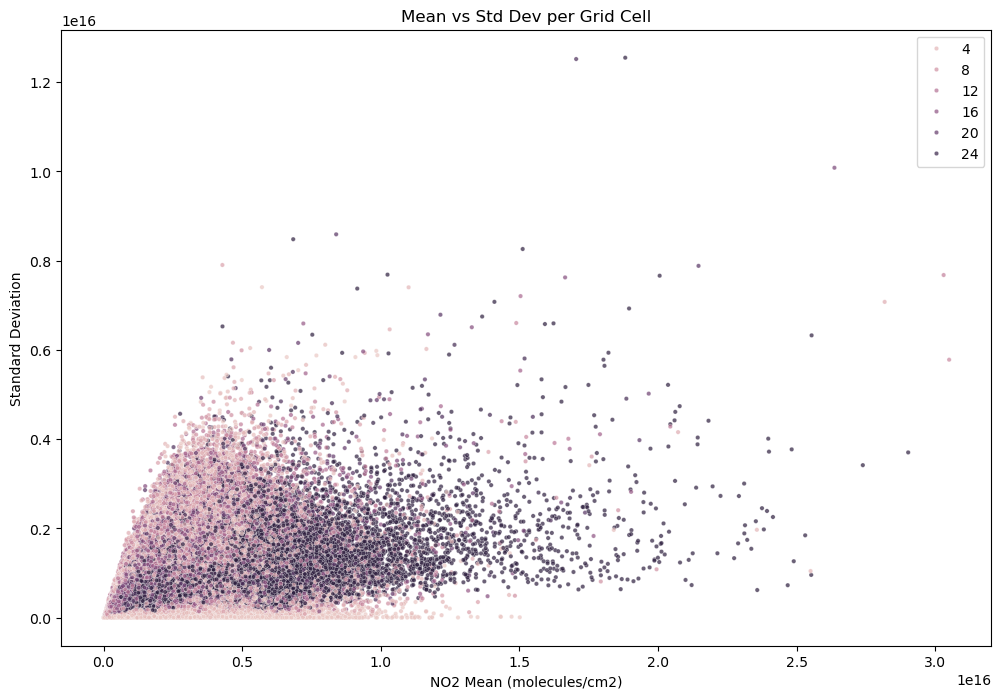

In [20]:

plt.figure(figsize=(12,8))
sns.scatterplot(data=agg, x='no2_mean', y='no2_std', hue='no2_count', s=10, alpha=0.7)
plt.xlabel('NO2 Mean (molecules/cm2)')
plt.ylabel('Standard Deviation')
plt.legend()
plt.title('Mean vs Std Dev per Grid Cell')
plt.show()

/global/home/users/toireasamarie/.conda/envs/regrid_env2/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


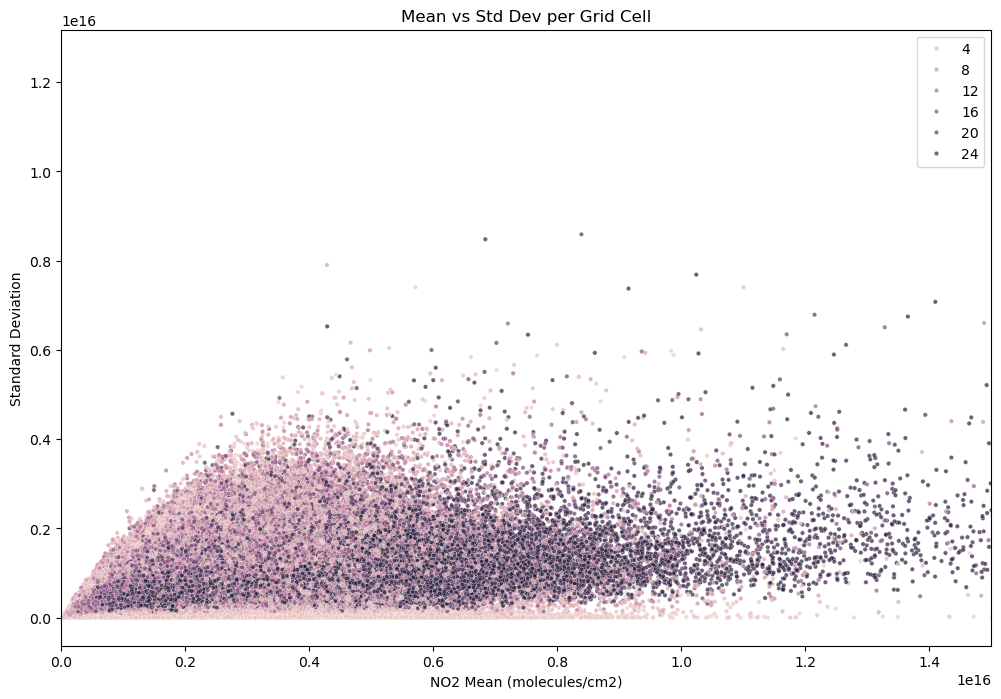

In [21]:
plt.figure(figsize=(12,8))
sns.scatterplot(data=agg, x='no2_mean', y='no2_std', hue='no2_count', s=10, alpha=0.7)
plt.xlabel('NO2 Mean (molecules/cm2)')
plt.xlim(0,1.5e16)
plt.ylabel('Standard Deviation')
plt.legend()
plt.title('Mean vs Std Dev per Grid Cell')
plt.show()

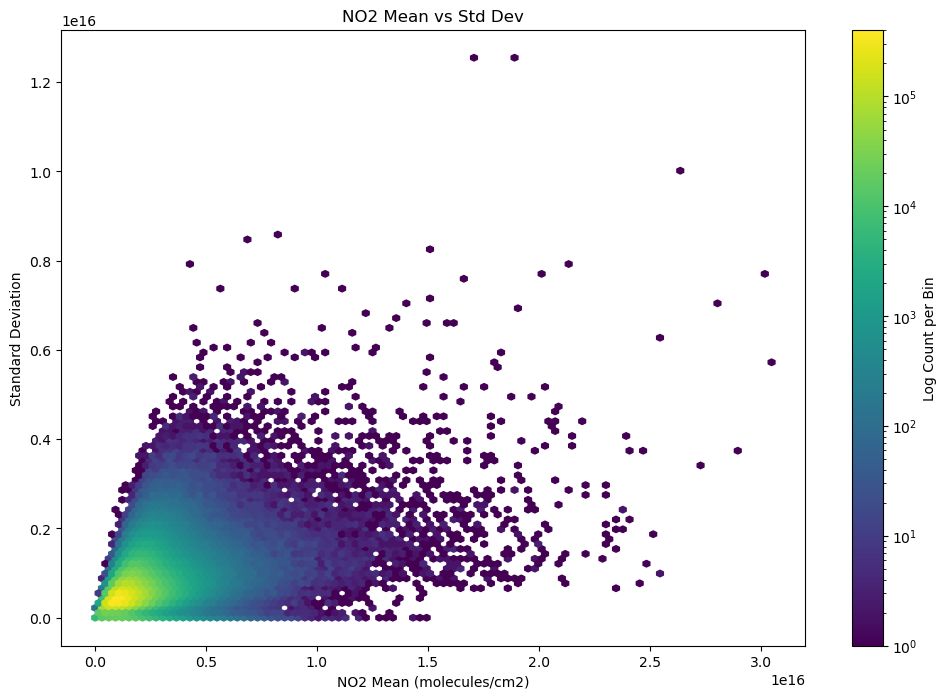

In [22]:
plt.figure(figsize=(12, 8))
hb = plt.hexbin(agg['no2_mean'], agg['no2_std'], gridsize=100, cmap='viridis', bins='log')
plt.colorbar(hb, label='Log Count per Bin')
plt.xlabel('NO2 Mean (molecules/cm2)')
plt.ylabel('Standard Deviation')
plt.title('NO2 Mean vs Std Dev')
plt.show()


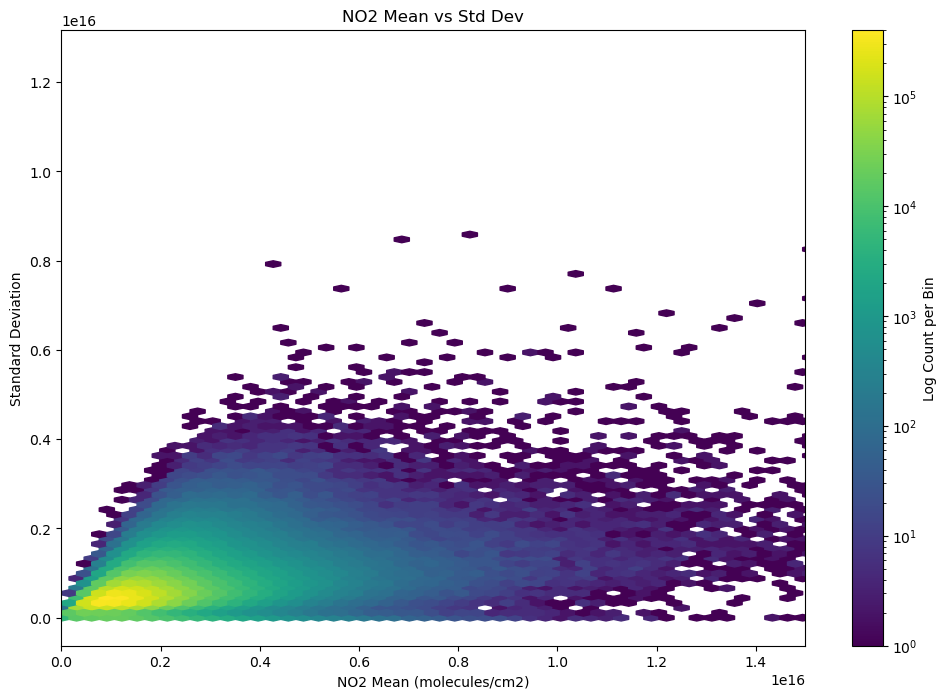

In [23]:
plt.figure(figsize=(12, 8))
hb = plt.hexbin(agg['no2_mean'], agg['no2_std'], gridsize=100, cmap='viridis', bins='log')
plt.colorbar(hb, label='Log Count per Bin')
plt.xlabel('NO2 Mean (molecules/cm2)')
plt.xlim(0, 1.5e16)
plt.ylabel('Standard Deviation')
plt.title('NO2 Mean vs Std Dev')
plt.show()


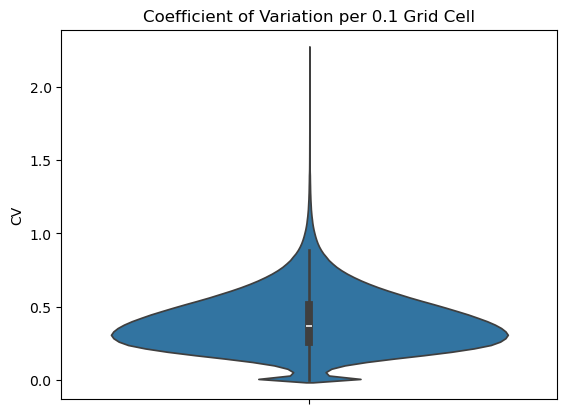

In [24]:
sns.violinplot(data=agg, y='cv', inner='box')
plt.title('Coefficient of Variation per 0.1 Grid Cell')
plt.ylabel('CV')
plt.show()

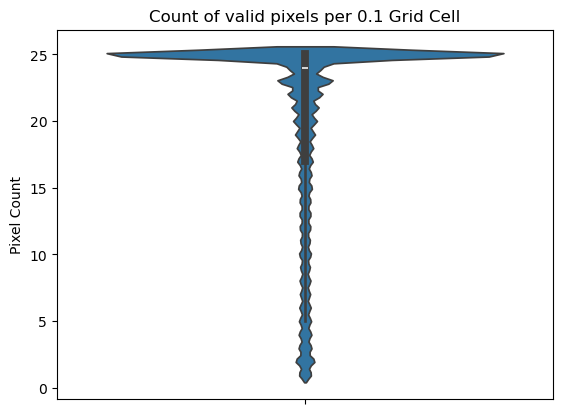

In [25]:
sns.violinplot(data=agg, y='no2_count', inner='box')
plt.title('Count of valid pixels per 0.1 Grid Cell')
plt.ylabel('Pixel Count')
plt.show()

In [26]:
agg

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,cv
0,2024-04-25 12:16:56.014576,36.049999,-85.349998,1.775310e+15,7.680691e+14,17,1.862841e+14,0.011109,0.000602,0.044334,0.002260,0.0,0.0,0.432639
1,2024-04-25 12:16:56.014576,36.049999,-85.250000,1.027563e+15,8.625617e+14,24,1.760697e+14,0.014190,0.002269,0.056559,0.008770,0.0,0.0,0.839424
2,2024-04-25 12:16:56.014576,36.049999,-85.150002,7.955970e+14,4.058840e+14,19,9.311618e+13,0.016752,0.000855,0.065923,0.003351,0.0,0.0,0.510163
3,2024-04-25 12:16:56.014576,36.049999,-85.049995,1.064539e+15,6.170416e+14,21,1.346495e+14,0.016511,0.001328,0.064659,0.005040,0.0,0.0,0.579633
4,2024-04-25 12:16:56.014576,36.049999,-84.949997,1.423508e+15,7.064138e+14,25,1.412828e+14,0.017117,0.000814,0.068054,0.003183,0.0,0.0,0.496248
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7277978,2024-07-31 23:33:15.032400,48.950001,-95.349998,2.756924e+15,4.827254e+14,25,9.654507e+13,0.067864,0.018153,0.188973,0.046095,0.0,0.0,0.175096
7277979,2024-07-31 23:33:15.032400,48.950001,-95.250000,2.746364e+15,4.957182e+14,25,9.914364e+13,0.057271,0.024379,0.156393,0.056953,0.0,0.0,0.180500
7277980,2024-07-31 23:33:15.032400,48.950001,-95.150002,3.524505e+15,4.941244e+14,21,1.078268e+14,0.087660,0.028652,0.228098,0.062248,0.0,0.0,0.140197
7277981,2024-07-31 23:33:15.032400,48.950001,-95.049995,3.126958e+15,6.857912e+14,17,1.663288e+14,0.109751,0.020376,0.279665,0.042613,0.0,0.0,0.219316


In [27]:
#need to make a condition where if have less than 12 no2_count, does not count as a valid pixel 

In [28]:
filtered_df = agg[agg['no2_count'] >= 12].copy()

In [29]:
filtered_df

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,cv
0,2024-04-25 12:16:56.014576,36.049999,-85.349998,1.775310e+15,7.680691e+14,17,1.862841e+14,0.011109,0.000602,0.044334,0.002260,0.0,0.0,0.432639
1,2024-04-25 12:16:56.014576,36.049999,-85.250000,1.027563e+15,8.625617e+14,24,1.760697e+14,0.014190,0.002269,0.056559,0.008770,0.0,0.0,0.839424
2,2024-04-25 12:16:56.014576,36.049999,-85.150002,7.955970e+14,4.058840e+14,19,9.311618e+13,0.016752,0.000855,0.065923,0.003351,0.0,0.0,0.510163
3,2024-04-25 12:16:56.014576,36.049999,-85.049995,1.064539e+15,6.170416e+14,21,1.346495e+14,0.016511,0.001328,0.064659,0.005040,0.0,0.0,0.579633
4,2024-04-25 12:16:56.014576,36.049999,-84.949997,1.423508e+15,7.064138e+14,25,1.412828e+14,0.017117,0.000814,0.068054,0.003183,0.0,0.0,0.496248
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7277975,2024-07-31 23:33:15.032400,48.950001,-97.849998,3.071308e+15,5.825329e+14,12,1.681628e+14,0.140192,0.006976,0.353784,0.012680,0.0,0.0,0.189669
7277978,2024-07-31 23:33:15.032400,48.950001,-95.349998,2.756924e+15,4.827254e+14,25,9.654507e+13,0.067864,0.018153,0.188973,0.046095,0.0,0.0,0.175096
7277979,2024-07-31 23:33:15.032400,48.950001,-95.250000,2.746364e+15,4.957182e+14,25,9.914364e+13,0.057271,0.024379,0.156393,0.056953,0.0,0.0,0.180500
7277980,2024-07-31 23:33:15.032400,48.950001,-95.150002,3.524505e+15,4.941244e+14,21,1.078268e+14,0.087660,0.028652,0.228098,0.062248,0.0,0.0,0.140197


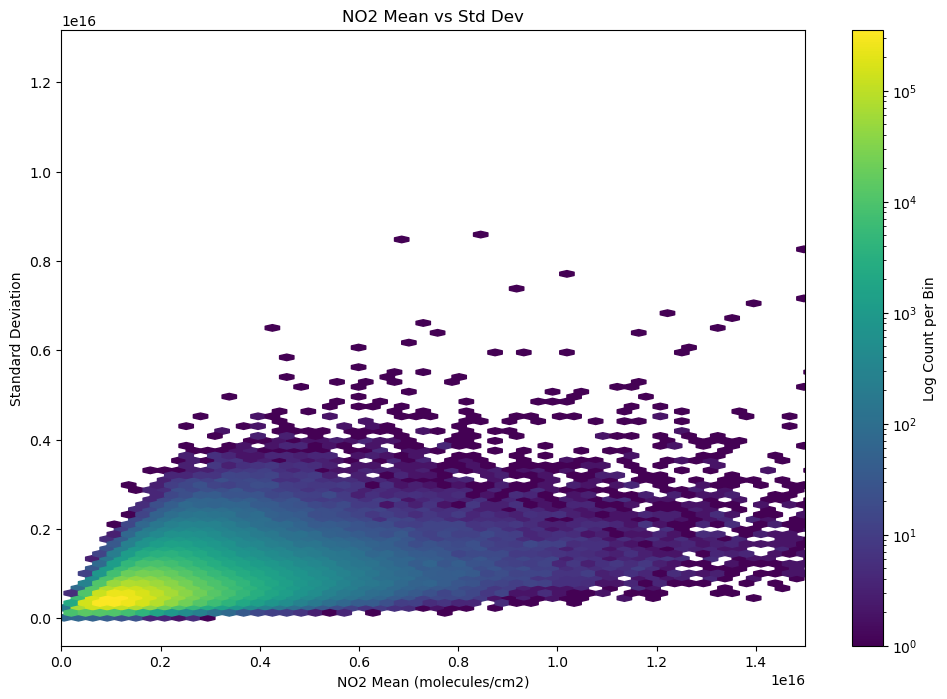

In [30]:
plt.figure(figsize=(12, 8))
hb = plt.hexbin(filtered_df['no2_mean'], filtered_df['no2_std'], gridsize=100, cmap='viridis', bins='log')
plt.colorbar(hb, label='Log Count per Bin')
plt.xlabel('NO2 Mean (molecules/cm2)')
plt.xlim(0, 1.5e16)
plt.ylabel('Standard Deviation')
plt.title('NO2 Mean vs Std Dev')
plt.show()


In [31]:
filtered_df= filtered_df.rename(columns={'cv':'cv_no2'})

In [32]:
filtered_df['datetime'] = pd.to_datetime(filtered_df['datetime'])

filtered_df['datetime'] = filtered_df['datetime'].dt.floor('h')

In [33]:
filtered_df

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2
0,2024-04-25 12:00:00,36.049999,-85.349998,1.775310e+15,7.680691e+14,17,1.862841e+14,0.011109,0.000602,0.044334,0.002260,0.0,0.0,0.432639
1,2024-04-25 12:00:00,36.049999,-85.250000,1.027563e+15,8.625617e+14,24,1.760697e+14,0.014190,0.002269,0.056559,0.008770,0.0,0.0,0.839424
2,2024-04-25 12:00:00,36.049999,-85.150002,7.955970e+14,4.058840e+14,19,9.311618e+13,0.016752,0.000855,0.065923,0.003351,0.0,0.0,0.510163
3,2024-04-25 12:00:00,36.049999,-85.049995,1.064539e+15,6.170416e+14,21,1.346495e+14,0.016511,0.001328,0.064659,0.005040,0.0,0.0,0.579633
4,2024-04-25 12:00:00,36.049999,-84.949997,1.423508e+15,7.064138e+14,25,1.412828e+14,0.017117,0.000814,0.068054,0.003183,0.0,0.0,0.496248
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7277975,2024-07-31 23:00:00,48.950001,-97.849998,3.071308e+15,5.825329e+14,12,1.681628e+14,0.140192,0.006976,0.353784,0.012680,0.0,0.0,0.189669
7277978,2024-07-31 23:00:00,48.950001,-95.349998,2.756924e+15,4.827254e+14,25,9.654507e+13,0.067864,0.018153,0.188973,0.046095,0.0,0.0,0.175096
7277979,2024-07-31 23:00:00,48.950001,-95.250000,2.746364e+15,4.957182e+14,25,9.914364e+13,0.057271,0.024379,0.156393,0.056953,0.0,0.0,0.180500
7277980,2024-07-31 23:00:00,48.950001,-95.150002,3.524505e+15,4.941244e+14,21,1.078268e+14,0.087660,0.028652,0.228098,0.062248,0.0,0.0,0.140197


In [34]:
output_parquet= '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/midwest_TEMPO_V04_0.1x0.1_gridded_apr_jul.parquet'
filtered_df.to_parquet(output_parquet, engine='pyarrow')